In [1]:
START_NEW_RUN = False  # False resumes this task's completed instances without training them twice.
RUN_ID = None
STAGE_LIMIT = 'A'  # A or B. This completed run did not qualify C/D; no unregistered extra training.
if STAGE_LIMIT not in ['A','B']:raise ValueError('本轮仅注册A/B；C/D未触发，禁止启动未登记训练。')

from pathlib import Path
import sys
if '__file__' in globals():FOLDER=Path(__file__).resolve().parent
else:
    options=[Path.cwd(),Path.cwd()/'F2_Performance_Improvement',Path.cwd()/'RENew-PEMFC-2300h-Pytorch/F2_Performance_Improvement']
    FOLDER=next(p for p in options if (p/'frozen_f2.py').exists())
if str(FOLDER) not in sys.path:sys.path.insert(0,str(FOLDER))
for module_name in ['frozen_f2','settings','diagnostics','train','io_utils','selection','stage_a','protocol',
    'history_diagnosis','report_a','verify_stage','stage_b','residual_fusion','report_b','repeat_diagnosis',
    'phase_flow','final_reports','artifact_index','final_integrity']:
    loaded=sys.modules.get(module_name)
    if loaded is not None and getattr(loaded,'__file__',None) and Path(loaded.__file__).resolve().parent!=FOLDER:
        raise RuntimeError('请重启VS Code Python交互内核：检测到其他目录的同名模块 '+module_name)
import frozen_f2 as f
from protocol import prepare
from history_diagnosis import analyze
from stage_a import run_stage
from IPython.display import display,Markdown
STAGE_LIMIT='B'


In [2]:
if RUN_ID is None and not START_NEW_RUN and (FOLDER/'ACTIVE_RUN.json').exists():RUN_ID=f.read_json(FOLDER/'ACTIVE_RUN.json')['run']
if RUN_ID is None:
    run,frame,windows,scaler,prepared=prepare()
else:
    run=FOLDER/'outputs'/RUN_ID
    f.require(f.read_json(run/'P0_ACCEPTANCE.json')['status']=='PASS','P0_REQUIRED')
    f.configure_environment();frame,windows,scaler,prepared,excluded=f.load_selection_data()
if not (run/'historical/IDENTITY_AUDIT.json').exists():analyze(run,frame,windows,scaler,prepared)
f.model_identity()
f.require(f.sha(f.SOURCE)==f.read_json(run/'PROTOCOL.json')['data_sha256'],'FROZEN_DATA_CHANGED')
for name,digest in f.read_json(run/'CODE_BEFORE_A.json').items():
    f.require(f.sha(FOLDER/name)==digest,'FROZEN_MATHEMATICAL_SOURCE_CHANGED:'+name)
display(Markdown('**Train/Validation identity passed.** Native F2, Top10, 1750/218 windows. No holdout windows or new scores.'))

**Train/Validation identity passed.** Native F2, Top10, 1750/218 windows. No holdout windows or new scores.

In [3]:
a_result=run_stage(run,frame,windows,scaler,prepared)
display(f.read_csv(run/'tables/A_VALIDATION_PER_SEED.csv'))
display(f.read_csv(run/'tables/A_VALIDATION_MEAN_SD.csv'))
print('STAGE_A_FINISHED',run,flush=True)

,candidate,seed,best_epoch,stop_epoch,training_seconds,parameters,partition,RMSE_mV,MAE_mV,R2,...,event_R2,event_queries,event_origins,event_unique_targets,non_event_RMSE_mV,non_event_MAE_mV,non_event_R2,non_event_queries,non_event_origins,non_event_unique_targets
0,A0,202,173,213,725.509048,332436,VALIDATION,6.708576,4.228541,0.998833,...,0.998156,1115,218,56,6.209046,4.114640,0.998059,4117,218,208
1,A0,212,95,135,463.100424,332436,VALIDATION,25.065725,8.905457,0.983714,...,0.941673,1115,218,56,14.455808,7.562332,0.989477,4117,218,208
2,A0,42,86,126,432.817514,332436,VALIDATION,12.702993,7.702274,0.995817,...,0.991049,1115,218,56,10.705476,7.837851,0.994229,4117,218,208
3,A1,202,117,157,538.305423,332436,VALIDATION,14.776675,7.446019,0.994340,...,0.994361,1115,218,56,14.849112,7.359220,0.988896,4117,218,208
4,A1,212,189,229,789.108090,332436,VALIDATION,9.809590,6.530124,0.997506,...,0.998319,1115,218,56,10.261623,6.923019,0.994697,4117,218,208
5,A1,42,259,299,1019.391743,332436,VALIDATION,12.208768,6.475014,0.996136,...,0.994944,1115,218,56,11.760958,6.666026,0.993035,4117,218,208
6,A2,202,177,217,746.179171,332436,VALIDATION,18.908304,7.481594,0.990732,...,0.982315,1115,218,56,16.601687,7.320865,0.986121,4117,218,208
7,A2,212,92,132,452.808772,332436,VALIDATION,23.212283,12.476024,0.986033,...,0.964354,1115,218,56,18.013174,10.946249,0.983660,4117,218,208
8,A2,42,117,157,538.197701,332436,VALIDATION,35.784158,9.937325,0.966807,...,0.931528,1115,218,56,30.582562,8.790587,0.952901,4117,218,208


,candidate,n,RMSE_mV_mean,MAE_mV_mean,R2_mean,P99_mV_mean,RMSE_mV_SD,MAE_mV_SD,R2_SD,P99_mV_SD
0,A0,3,14.825764,6.945424,0.992788,40.962887,9.360868,2.428580,0.008002,19.147266
1,A1,3,12.265011,6.817052,0.995994,29.168893,2.484020,0.545398,0.001588,2.054344
2,A2,3,25.968248,9.964981,0.981191,136.133237,8.768987,2.497330,0.012676,128.447802


STAGE_A_FINISHED E:\沈农信电\ PEMFC-SOH+RUL\RENew-PEMFC-2300h-Pytorch\F2_Performance_Improvement\outputs\20261020T043811_940866Z_F2_improvement


In [4]:
from verify_stage import verify
if not (run/'audits/A_INDEPENDENT_AUDIT.json').exists():verify(run,'A')
else:f.require(f.read_json(run/'audits/A_INDEPENDENT_AUDIT.json')['status']=='PASS','A_AUDIT_NOT_PASS')

In [5]:
if STAGE_LIMIT=='B':
    from stage_b import run_stage as run_b
    b_result=run_b(run,frame,windows,scaler,prepared)
    display(f.read_csv(run/'tables/B_VALIDATION_PER_SEED.csv'))
    display(f.read_csv(run/'tables/B_VALIDATION_MEAN_SD.csv'))

,candidate,seed,best_epoch,stop_epoch,training_seconds,parameters,partition,RMSE_mV,MAE_mV,R2,...,event_R2,event_queries,event_origins,event_unique_targets,non_event_RMSE_mV,non_event_MAE_mV,non_event_R2,non_event_queries,non_event_origins,non_event_unique_targets
0,B_control,202,78,118,407.192199,332436,VALIDATION,9.806180,6.661918,0.997507,...,0.997436,1115,218,56,9.812872,6.821081,0.995151,4117,218,208
1,B_control,212,149,189,656.581560,332436,VALIDATION,12.746952,5.973578,0.995788,...,0.991073,1115,218,56,10.782800,5.988294,0.994145,4117,218,208
2,B_control,42,75,115,399.811931,332436,VALIDATION,30.900509,13.530807,0.975249,...,0.944999,1115,218,56,25.643232,12.148101,0.966886,4117,218,208
3,B_v2,202,45,85,298.982249,332436,VALIDATION,27.310003,11.887943,0.980667,...,0.924167,1115,218,56,13.469403,8.821550,0.990864,4117,218,208
4,B_v2,212,88,128,451.534385,332436,VALIDATION,15.731785,8.076713,0.993585,...,0.986002,1115,218,56,13.154640,7.746186,0.991286,4117,218,208
5,B_v2,42,209,249,871.374255,332436,VALIDATION,10.833207,6.448353,0.996958,...,0.994531,1115,218,56,9.688881,6.676220,0.995273,4117,218,208


,candidate,n,RMSE_mV_mean,MAE_mV_mean,R2_mean,P99_mV_mean,RMSE_mV_SD,MAE_mV_SD,R2_SD,P99_mV_SD
0,B_control,3,17.817881,8.722101,0.989515,64.906931,11.424903,4.178660,0.012384,63.906701
1,B_v2,3,17.958332,8.804337,0.990403,61.954033,8.461048,2.791838,0.008599,34.128723


In [6]:
if STAGE_LIMIT=='B':
    if not (run/'audits/B_INDEPENDENT_AUDIT.json').exists():verify(run,'B')
    else:f.require(f.read_json(run/'audits/B_INDEPENDENT_AUDIT.json')['status']=='PASS','B_AUDIT_NOT_PASS')

,candidate,n,RMSE_mV_mean,MAE_mV_mean,R2_mean,P99_mV_mean,RMSE_mV_SD,MAE_mV_SD,R2_SD,P99_mV_SD,stage,partition,queries_per_model,new_training
0,A0,3,14.825764,6.945424,0.992788,40.962887,9.360868,2.428580,0.008002,19.147266,A,VALIDATION,5232,True
1,A1,3,12.265011,6.817052,0.995994,29.168893,2.484020,0.545398,0.001588,2.054344,A,VALIDATION,5232,True
2,A2,3,25.968248,9.964981,0.981191,136.133237,8.768987,2.497330,0.012676,128.447802,A,VALIDATION,5232,True
3,B_control,3,17.817881,8.722101,0.989515,64.906931,11.424903,4.178660,0.012384,63.906701,B,VALIDATION,5232,True
4,B_v2,3,17.958332,8.804337,0.990403,61.954033,8.461048,2.791838,0.008599,34.128723,B,VALIDATION,5232,True


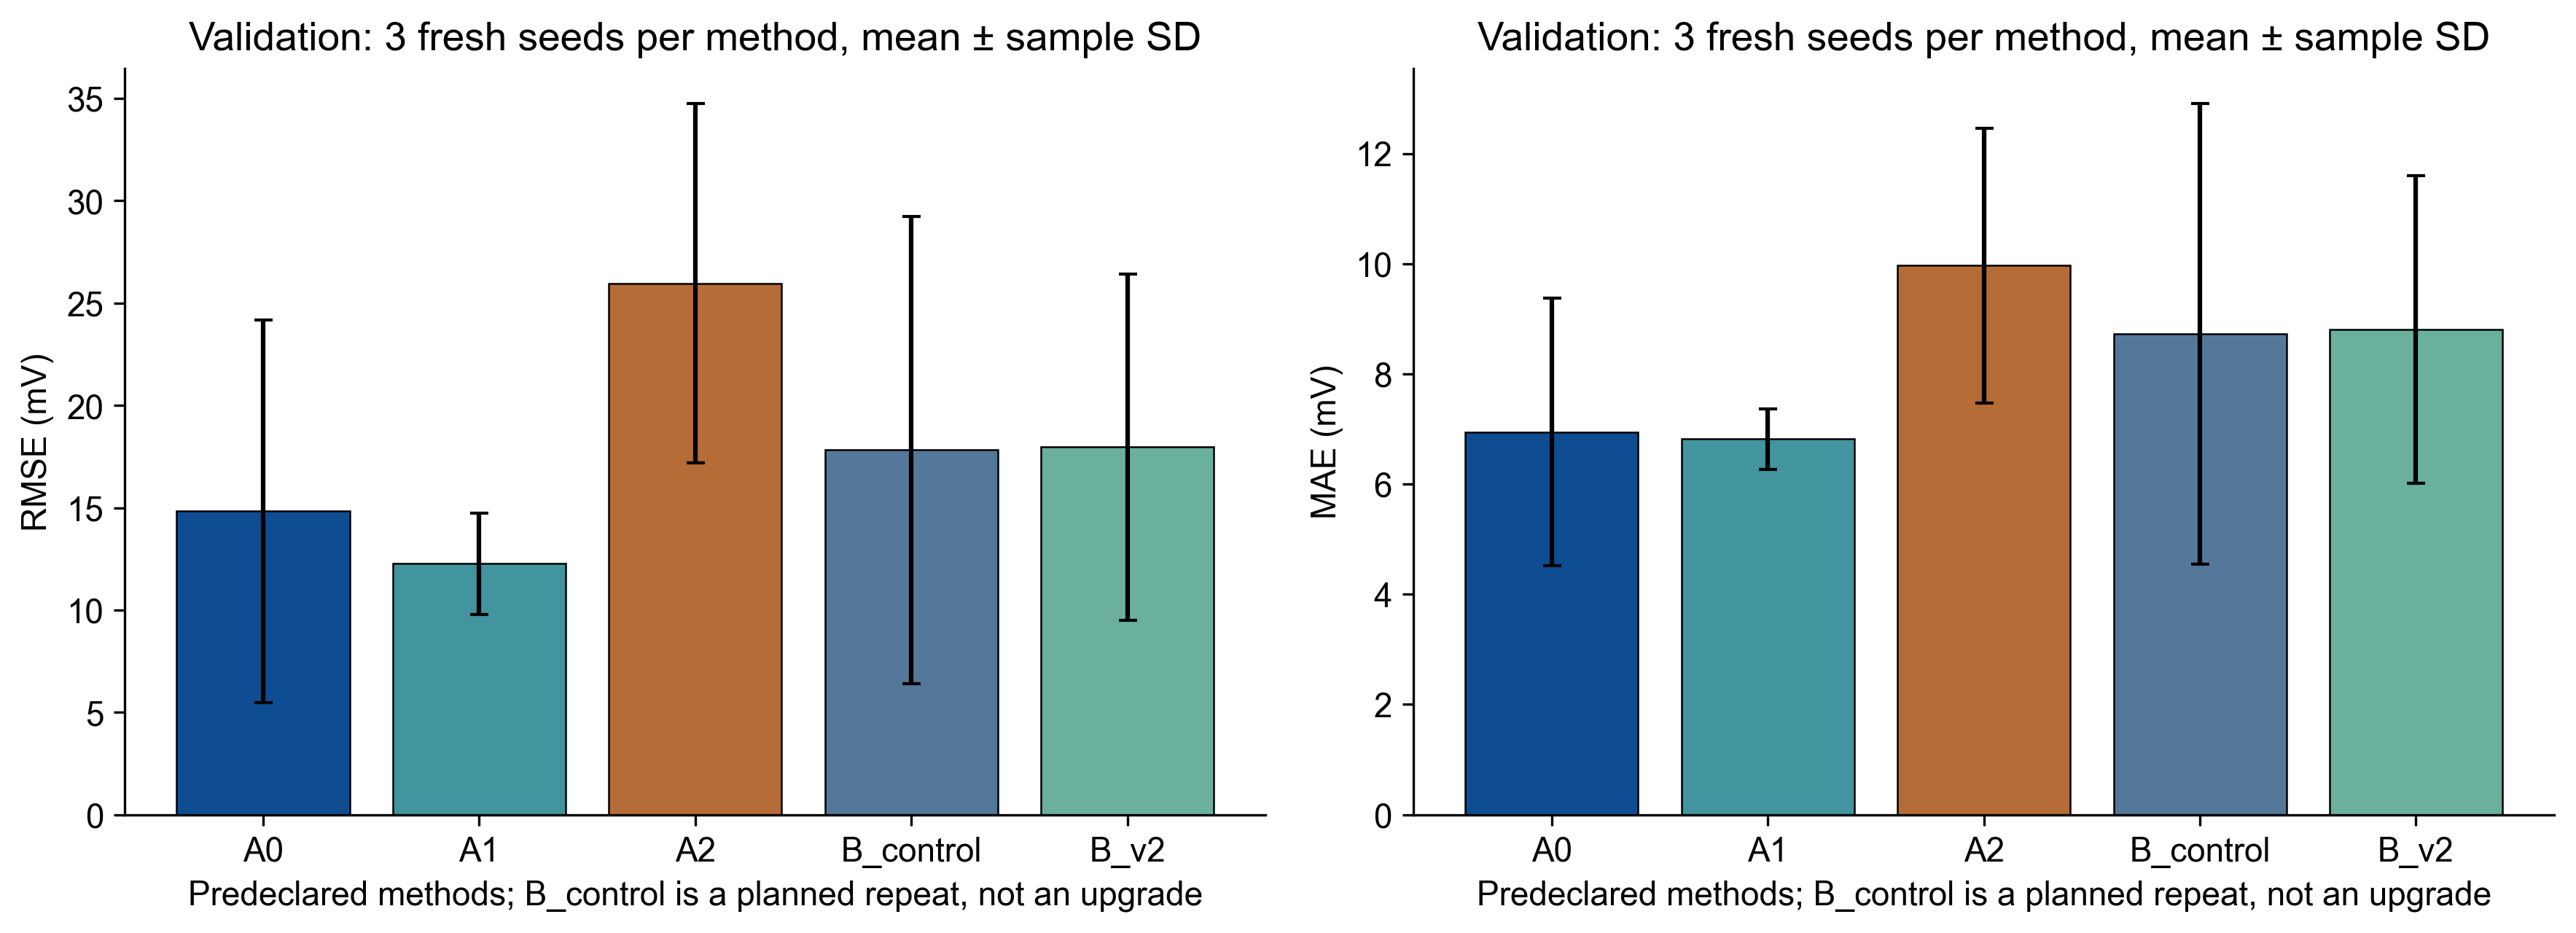

NO_QUALIFIED_UPGRADE: A9+B6真实新训练已完成；C/D未触发，新后留指标NA。


In [7]:
if STAGE_LIMIT=='B':
    from phase_flow import review_ab,stop_if_no_upgrade
    review=review_ab(run)
    if review['eligible_candidates']:
        display(Markdown('存在合格前置候选。必须先完成C/D独立预注册；本入口不启动未登记训练。'))
    else:
        stop_if_no_upgrade(run)
        if not (run/'04_最终研究总结.md').exists():
            from final_reports import write_stopped
            write_stopped(run)
        from IPython.display import Image
        display(f.read_csv(run/'tables/FINAL_VALIDATION_STUDY_SUMMARY.csv'))
        display(Image(filename=str(run/'figures/FINAL/01_Validation_study_summary.png')))
        print('NO_QUALIFIED_UPGRADE: A9+B6真实新训练已完成；C/D未触发，新后留指标NA。',flush=True)